# 001 — ankle vs waist acceleration comparison (first pass)

Annotation export: `001_120fps_ffv1.csv` (multi-mass tracking).

- **ankle = mass B**, **waist / sacro = mass A**
- Waist data has gaps (≈0.33–1.01 s and ≈1.26–1.40 s) and the ankle tail ends at 3.025 s. Gaps are kept as **NaN** — no interpolation anywhere.
- Coordinates are annotation units (consistent with metres, unverified), so accelerations are in **u/s²**.

Method: Savitzky–Golay differentiation (window 21 frames, order 3) applied **inside each contiguous segment only** (edges and gaps stay NaN).

Environment: run from the pixi project — `cd /Users/rifusaki/localRepos/uni/one-off && pixi run jupyter lab` (the pixi env has numpy/pandas/matplotlib; scipy is not needed here).

In [13]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

FILE_NAME = "001_120fps_ffv1.csv"   # change for 002 / 003
FS = 120.0                # nominal fps of the normalized clip (measured: 119.935 -> 0.05% effect)
SG_WINDOW = 21            # ~0.175 s at 120 fps
SG_ORDER = 3
EVENT_MIN_DIST_S = 0.5    # minimum spacing between detected events
EVENT_DEPTH = 0.03        # min depth below the local envelope to accept an ankle low [units]
EVENT_HALFWIDTH_S = 0.25  # half-width of the envelope used for the depth test
IMPACT_WINDOW_S = 0.08    # +/- window around an event for peak comparison


def find_data_file(name: str) -> Path:
    """Locate the annotation CSV from common working directories."""
    here = Path.cwd()
    candidates = [
        here / name,
        here / "walkTest" / "normalized" / name,
        here / "invexp" / "walkTest" / "normalized" / name,
        here.parent / "walkTest" / "normalized" / name,
    ]
    for c in candidates:
        if c.exists():
            return c
    matches = sorted(here.rglob(name))
    if matches:
        return matches[0]
    raise FileNotFoundError(f"{name} not found from {here}")


DATA = find_data_file(FILE_NAME)
print("file:", DATA)

file: /Users/rifusaki/localRepos/uni/invexp/walkTest/normalized/001_120fps_ffv1.csv


In [14]:
def load_multimass_csv(path: Path) -> pd.DataFrame:
    """Parse the '#multi:' two-mass annotation export -> t, xA, yA, xB, yB."""
    return pd.read_csv(path, skiprows=3, header=None,
                       names=["t", "xA", "yA", "xB", "yB"], dtype=float)


def segments(mask: np.ndarray):
    """Contiguous runs of True, as (start, stop) index pairs."""
    idx = np.flatnonzero(mask)
    if len(idx) == 0:
        return []
    return [(int(s[0]), int(s[-1]))
            for s in np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)]


df = load_multimass_csv(DATA)
t = df["t"].to_numpy()

print(f"{len(df)} frames, {t[0]:.3f}-{t[-1]:.3f} s, mean dt = {np.diff(t).mean():.6f} s")
for label, col in [("A waist", df["xA"]), ("B ankle", df["xB"])]:
    mask = col.notna().to_numpy()
    print(f"\n{label}: {mask.sum()}/{len(df)} frames ({100 * mask.mean():.1f}%)")
    for a, b in segments(mask):
        print(f"   present {t[a]:6.3f} - {t[b]:6.3f} s")

387 frames, 0.000-3.217 s, mean dt = 0.008333 s

A waist: 288/387 frames (74.4%)
   present  0.025 -  0.333 s
   present  1.008 -  1.258 s
   present  1.400 -  3.217 s

B ankle: 364/387 frames (94.1%)
   present  0.000 -  3.025 s


In [15]:
def _sg_weights(window: int, order: int, deriv: int) -> np.ndarray:
    """Savitzky-Golay derivative weights at the window centre (per sample index)."""
    half = window // 2
    x = np.arange(-half, half + 1, dtype=float)
    A = np.vander(x, order + 1, increasing=True)
    return math.factorial(deriv) * np.linalg.pinv(A)[deriv]


def sg_derivative(y: np.ndarray, mask: np.ndarray, deriv: int,
                  window: int = SG_WINDOW, order: int = SG_ORDER) -> np.ndarray:
    """SG derivative computed separately inside each contiguous valid segment.

    NaN is kept at segment edges and across gaps (no interpolation).
    """
    half = window // 2
    w = _sg_weights(window, order, deriv)
    out = np.full(len(y), np.nan)
    for a, b in segments(mask):
        seg = y[a:b + 1]
        for i in range(half, len(seg) - half):
            out[a + i] = float(np.dot(w, seg[i - half:i + half + 1]))
    return out


def derivative(y: np.ndarray, mask: np.ndarray, deriv: int) -> np.ndarray:
    """SG derivative in physical units (FS**deriv)."""
    return sg_derivative(y, mask, deriv) * FS ** deriv

In [16]:
maskA = df["xA"].notna().to_numpy()   # waist
maskB = df["xB"].notna().to_numpy()   # ankle

# ankle (B)
vB_x = derivative(df["xB"].to_numpy(), maskB, 1)
vB_y = derivative(df["yB"].to_numpy(), maskB, 1)
aB_x = derivative(df["xB"].to_numpy(), maskB, 2)
aB_y = derivative(df["yB"].to_numpy(), maskB, 2)
# waist (A)
vA_x = derivative(df["xA"].to_numpy(), maskA, 1)
vA_y = derivative(df["yA"].to_numpy(), maskA, 1)
aA_x = derivative(df["xA"].to_numpy(), maskA, 2)
aA_y = derivative(df["yA"].to_numpy(), maskA, 2)

aB_mag = np.hypot(aB_x, aB_y)   # resultant of horizontal + vertical
aA_mag = np.hypot(aA_x, aA_y)

print(f"max |a_y|   ankle {np.nanmax(np.abs(aB_y)):6.2f}   waist {np.nanmax(np.abs(aA_y)):6.2f}   u/s²")
print(f"max |a|     ankle {np.nanmax(aB_mag):6.2f}   waist {np.nanmax(aA_mag):6.2f}   u/s²")

max |a_y|   ankle  12.27   waist   4.72   u/s²
max |a|     ankle  36.69   waist   5.07   u/s²


## Three views: resultant, horizontal, vertical

Each figure carries the whole kinematic chain for both markers — **position,
velocity, acceleration** — in one component view:

1. **resultant** — `|r - r̄|`, `|v|`, `|a|`
2. **horizontal** — `x`, `v_x`, `a_x`
3. **vertical** — `y`, `v_y`, `a_y`

Resultant position is measured from each marker's mean position (`r̄`), because
the raw sensor offset would otherwise dominate the magnitude. Nothing is
interpolated: waist gaps stay line breaks, and the SG window (`SG_WINDOW = 21`
→ ±10 frames ≈ ±0.083 s) keeps every derivative NaN at segment edges.


In [17]:
xA = df["xA"].to_numpy()
yA = df["yA"].to_numpy()
xB = df["xB"].to_numpy()
yB = df["yB"].to_numpy()

# Resultant position from each marker's own mean over its valid samples,
# otherwise the constant sensor offset dominates the magnitude.
rA_mag = np.hypot(xA - np.nanmean(xA[maskA]), yA - np.nanmean(yA[maskA]))
rB_mag = np.hypot(xB - np.nanmean(xB[maskB]), yB - np.nanmean(yB[maskB]))

vA_mag = np.hypot(vA_x, vA_y)
vB_mag = np.hypot(vB_x, vB_y)

for label, vx, vy, v_mag in [("ankle", vB_x, vB_y, vB_mag),
                             ("waist", vA_x, vA_y, vA_mag)]:
    print(f"{label:5s} max |v_x| {np.nanmax(np.abs(vx)):6.3f}   "
          f"max |v_y| {np.nanmax(np.abs(vy)):6.3f}   "
          f"max |v| {np.nanmax(v_mag):6.3f}   u/s")

ANKLE_C, WAIST_C = "#0f7b6c", "#b8431f"


def plot_pair(ax, waist, ankle, ylabel: str, title: str,
              zero_line: bool = False) -> None:
    """Waist + ankle on one axis. NaN (gaps, SG edges) stays a line break."""
    ax.plot(t, ankle, lw=0.9, color=ANKLE_C, label="ankle (B)")
    ax.plot(t, waist, lw=0.9, color=WAIST_C, label="waist (A)")
    if zero_line:
        ax.axhline(0.0, color="0.35", lw=0.5, alpha=0.6, zorder=0)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=10)
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)


ankle max |v_x|  4.111   max |v_y|  0.960   max |v|  4.154   u/s
waist max |v_x|  1.704   max |v_y|  0.393   max |v|  1.716   u/s


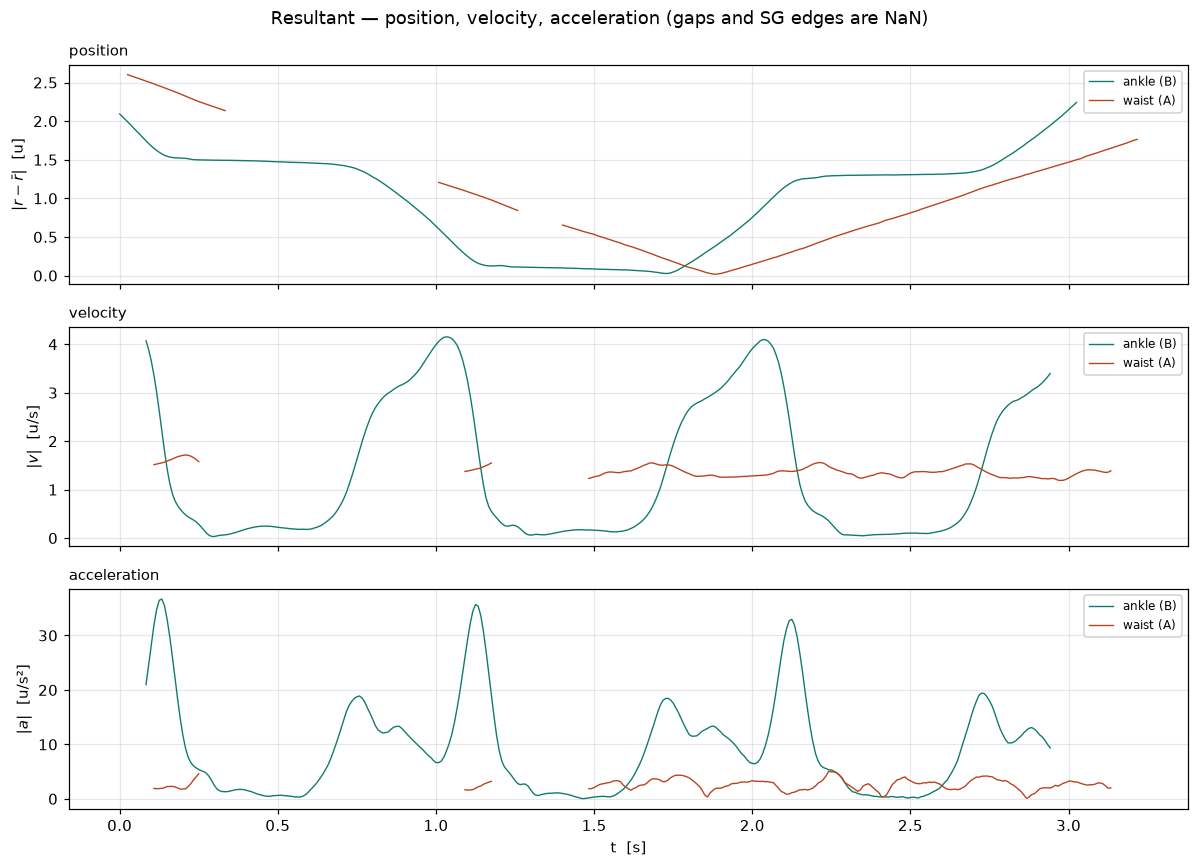

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

plot_pair(axes[0], rA_mag, rB_mag, r"$|r - \bar{r}|$  [u]", "position")
plot_pair(axes[1], vA_mag, vB_mag, "$|v|$  [u/s]", "velocity")
plot_pair(axes[2], aA_mag, aB_mag, "$|a|$  [u/s²]", "acceleration")

axes[2].set_xlabel("t  [s]")
fig.suptitle("Resultant — position, velocity, acceleration (gaps and SG edges are NaN)")
fig.tight_layout()
plt.show()


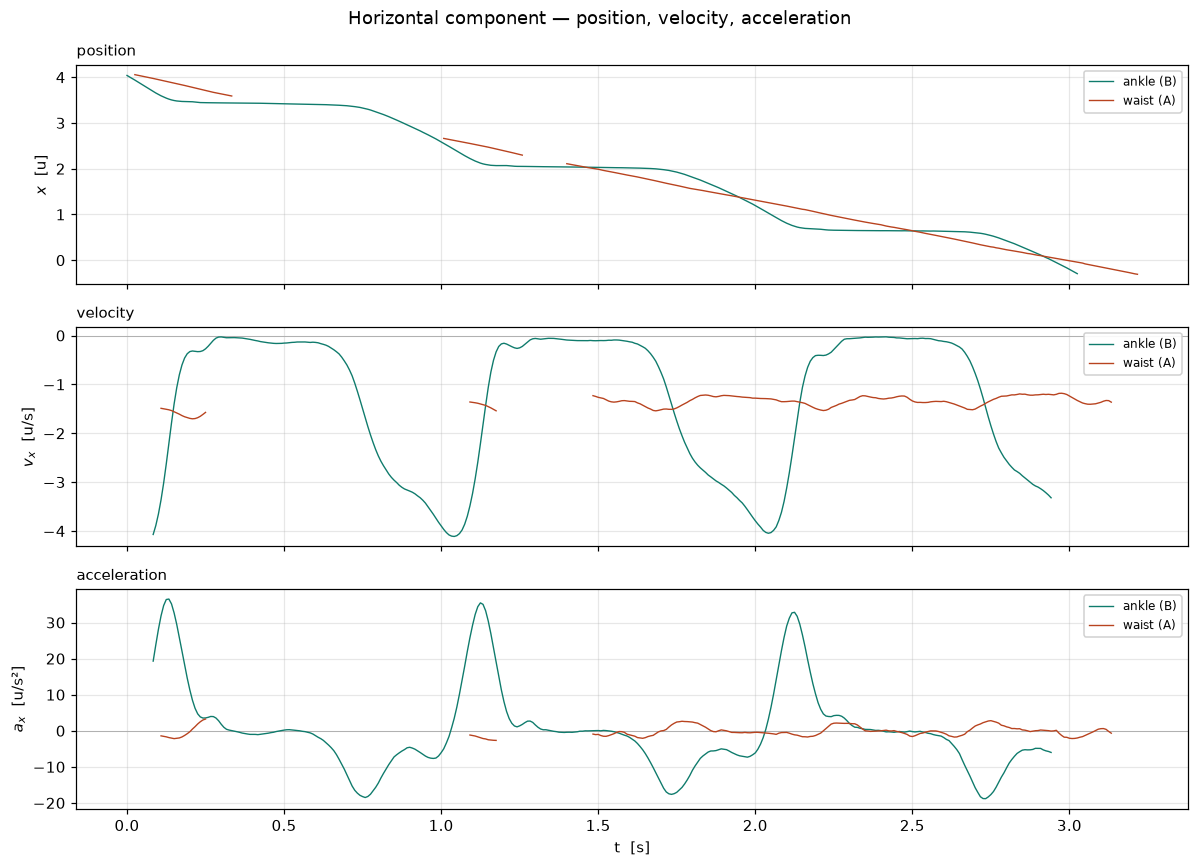

In [19]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

plot_pair(axes[0], xA, xB, "$x$  [u]", "position")
plot_pair(axes[1], vA_x, vB_x, "$v_x$  [u/s]", "velocity", zero_line=True)
plot_pair(axes[2], aA_x, aB_x, "$a_x$  [u/s²]", "acceleration", zero_line=True)

axes[2].set_xlabel("t  [s]")
fig.suptitle("Horizontal component — position, velocity, acceleration")
fig.tight_layout()
plt.show()


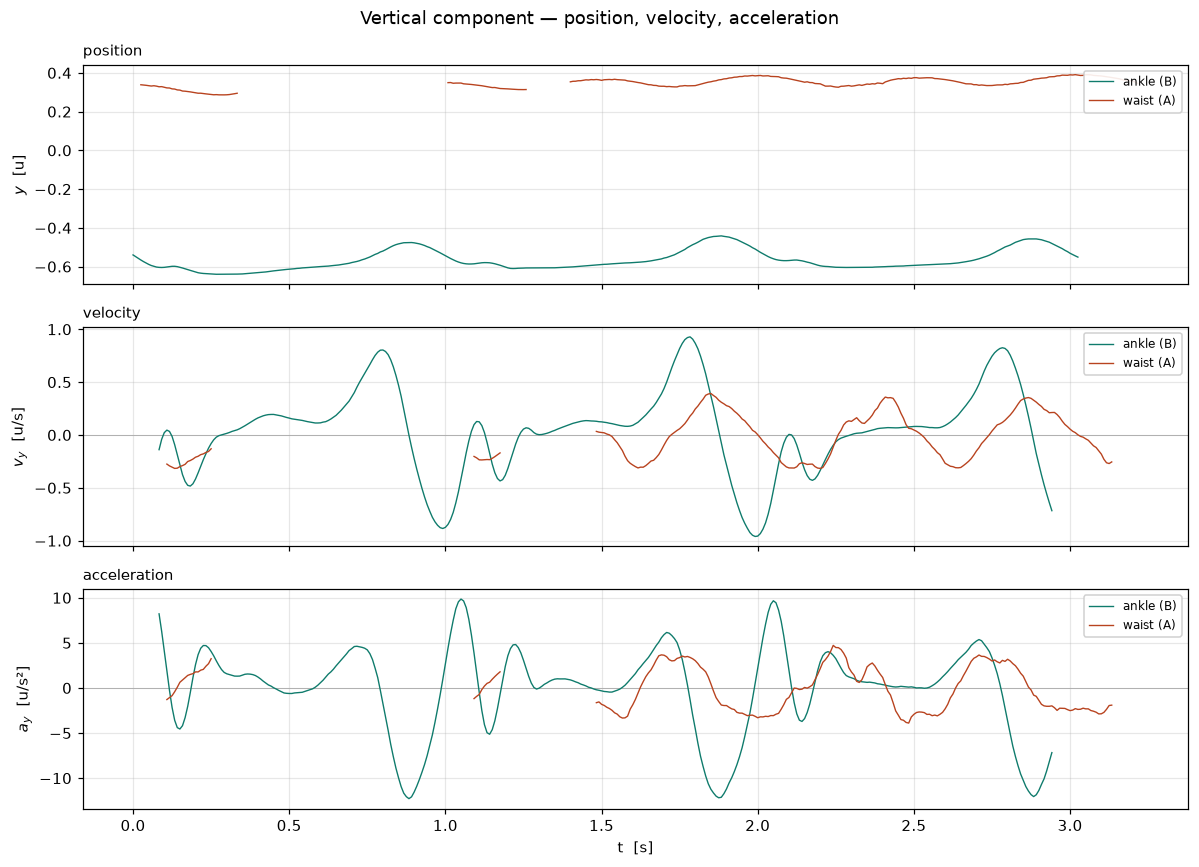

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

plot_pair(axes[0], yA, yB, "$y$  [u]", "position")
plot_pair(axes[1], vA_y, vB_y, "$v_y$  [u/s]", "velocity", zero_line=True)
plot_pair(axes[2], aA_y, aB_y, "$a_y$  [u/s²]", "acceleration", zero_line=True)

axes[2].set_xlabel("t  [s]")
fig.suptitle("Vertical component — position, velocity, acceleration")
fig.tight_layout()
plt.show()


In [21]:
def find_events(y: np.ndarray, mask: np.ndarray):
    """Ankle vertical lows: local minima with a depth filter and minimum spacing.

    A candidate is kept only if it lies at least EVENT_DEPTH below the maximum of
    its +/- EVENT_HALFWIDTH_S neighbourhood (rejects flat plateau wobbles), and the
    deepest candidates are chosen greedily subject to EVENT_MIN_DIST_S.
    """
    dist = int(round(EVENT_MIN_DIST_S * FS))
    hw = int(round(EVENT_HALFWIDTH_S * FS))
    cand = []
    for i in range(1, len(y) - 1):
        if not (mask[i - 1] and mask[i] and mask[i + 1]):
            continue
        if y[i] < y[i - 1] and y[i] <= y[i + 1]:
            env = y[max(0, i - hw):i + hw + 1]
            if y[i] <= np.nanmax(env) - EVENT_DEPTH:
                cand.append(i)
    kept = []
    for i in sorted(cand, key=lambda k: y[k]):
        if all(abs(i - j) >= dist for j in kept):
            kept.append(i)
    return np.sort(np.array(kept, dtype=int))


yB = df["yB"].to_numpy()
events = find_events(yB, maskB)

print(f"{len(events)} candidate events (ankle vertical lows):")
for i in events:
    print(f"   t = {t[i]:6.3f} s    yB = {yB[i]:.3f}")
if len(events) > 1:
    d = np.diff(t[events])
    print("   spacing [s]:", np.round(d, 3), f"  (mean {d.mean():.3f} s)")

3 candidate events (ankle vertical lows):
   t =  0.258 s    yB = -0.640
   t =  1.217 s    yB = -0.610
   t =  2.283 s    yB = -0.604
   spacing [s]: [0.958 1.067]   (mean 1.012 s)


In [22]:
def pk(v: np.ndarray) -> float:
    """Max absolute value, NaN if the slice is entirely NaN."""
    return float(np.nanmax(v)) if np.isfinite(v).any() else float("nan")


impact = int(round(IMPACT_WINDOW_S * FS))
rows = []
for i in events:
    sl = slice(max(0, i - impact), min(len(t), i + impact + 1))
    ay_B, ay_A = np.abs(aB_y[sl]), np.abs(aA_y[sl])
    mB, mA = aB_mag[sl], aA_mag[sl]
    rows.append({
        "t_event [s]": round(float(t[i]), 3),
        "peak |a_y| ankle": pk(ay_B),
        "peak |a_y| waist": pk(ay_A),
        "T_y = waist/ankle": pk(ay_A) / pk(ay_B) if pk(ay_B) > 0 else float("nan"),
        "peak |a| ankle": pk(mB),
        "peak |a| waist": pk(mA),
        "T_|a| = waist/ankle": pk(mA) / pk(mB) if pk(mB) > 0 else float("nan"),
    })

events_tbl = pd.DataFrame(rows)
print(events_tbl.round(3).to_string(index=False))
print("\nmedian T_y:", round(float(events_tbl['T_y = waist/ankle'].median()), 3))

 t_event [s]  peak |a_y| ankle  peak |a_y| waist  T_y = waist/ankle  peak |a| ankle  peak |a| waist  T_|a| = waist/ankle
       0.258             4.708             3.244              0.689          22.182           4.593                0.207
       1.217             5.128             1.787              0.349          35.393           3.213                0.091
       2.283             4.027             4.722              1.173           8.288           5.074                0.612

median T_y: 0.689


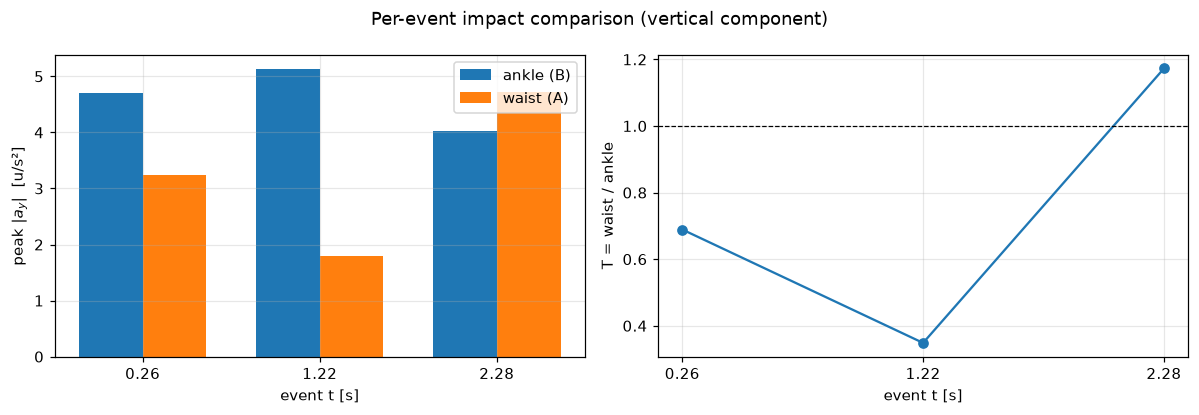

In [23]:
xs = np.arange(len(events_tbl))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(xs - 0.18, events_tbl["peak |a_y| ankle"], width=0.36, label="ankle (B)")
axes[0].bar(xs + 0.18, events_tbl["peak |a_y| waist"], width=0.36, label="waist (A)")
axes[0].set_ylabel("peak $|a_y|$  [u/s²]")
axes[0].legend()

axes[1].plot(xs, events_tbl["T_y = waist/ankle"], "o-")
axes[1].axhline(1.0, color="k", lw=0.8, ls="--")
axes[1].set_ylabel("T = waist / ankle")

for ax in axes:
    ax.set_xticks(xs)
    ax.set_xticklabels([f"{v:.2f}" for v in events_tbl["t_event [s]"]])
    ax.set_xlabel("event t [s]")

fig.suptitle("Per-event impact comparison (vertical component)")
fig.tight_layout()
plt.show()

## Reading these results

- **Events** are instants where the ankle marker reaches a local vertical low — a proxy for stance, not a pressure-verified heel strike. Impact windows: ±0.08 s around each event.
- **SG derivatives amplify annotation jitter.** Peaks are indicative, not calibrated accelerometry; expect sensitivity to the smoothing window.
- **Waist gaps**: comparisons overlapping a gap are skipped (NaN); nothing is interpolated.
- **Units**: annotation units (consistent with metres, unverified) → u, u/s, u/s².
- **Three component views** (resultant, horizontal, vertical) each show position,
  velocity and acceleration for both markers. Velocity and acceleration lose ±10
  frames (≈0.083 s) at every segment edge, because the SG window needs a full half
  window of valid samples. Resultant position is measured from each marker's mean
  position, since the raw offset dominates otherwise.
- **FS = 120 nominal**; measured 119.935 fps → 0.05 % effect, irrelevant at this precision.
- Next passes (not here yet): same plots for 002/003, coordinate differences, cross-correlation lag ankle→waist, FSR/sync-tap alignment.